# 虚假招聘检测——数据准备

本 Notebook 负责数据清洗、数据集划分、基线模型和 EDA 分析。

原始数据来自 EMSCAD，共17,880条招聘记录。

## 1. 数据清洗与划分

将5个文本字段合并为 `text_all`，处理缺失值并删除重复记录。清洗后保留15,879条数据。

使用分层抽样，按70%/15%/15%划分训练集、验证集和测试集，随机种子为42。

结果保存为 `jobs_clean.csv`。

In [2]:

# ============================================================
# Data Preparation and Data Splitting (v2)
# Project: Alert-Budgeted Detection of Fraudulent Job Postings
# ============================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from google.colab import files

RANDOM_STATE = 42

TEXT_COLS = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

# ============================================================
# Step 1: Upload and read the CSV file
# ============================================================

print("Step 1: Upload fake_job_postings.csv")


uploaded = files.upload()

# 获取本次上传的文件名
FILE_NAME = list(uploaded.keys())[0]

# 直接读取本次上传的文件
df = pd.read_csv(FILE_NAME)

print("Successfully loaded:", FILE_NAME)


print("\n===== Original Dataset =====")
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.to_string())

print("\nFirst 5 rows:")
display(df.head())

# ============================================================
# Step 2: Check missing values and label distribution
# ============================================================

print("\n===== Missing Values =====")

missing_count = df.isna().sum()

missing_rate = df.isna().mean() * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Rate (%)": missing_rate
})

display(missing_summary)

print("\n===== Original Label Distribution =====")

if "fraudulent" not in df.columns:
    raise ValueError("Missing fraudulent column")

if df["fraudulent"].isna().any():
    raise ValueError("Missing values found in fraudulent")

if not df["fraudulent"].isin([0, 1]).all():
    raise ValueError("fraudulent must contain only 0 and 1")

df["fraudulent"] = df["fraudulent"].astype(int)

label_summary = pd.DataFrame({
    "Count": df["fraudulent"].value_counts(),
    "Percentage (%)": (
        df["fraudulent"].value_counts(normalize=True) * 100
    )
}).sort_index()

display(label_summary)

# ============================================================
# Step 3: Check job_id and required text columns
# ============================================================

print("\n===== Checking Required Columns =====")

missing_cols = [
    col for col in TEXT_COLS if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing text columns: {missing_cols}"
    )

if "job_id" not in df.columns:
    df["job_id"] = np.arange(1, len(df) + 1)
    print("job_id generated from original row order.")
else:
    print("Existing job_id retained.")

if df["job_id"].isna().any():
    raise ValueError("job_id contains missing values")

df["job_id"] = df["job_id"].astype(str)

assert df["job_id"].is_unique, "job_id is not unique"

print("job_id is unique:", df["job_id"].is_unique)

# ============================================================
# Step 4: Combine text columns into text_all
# ============================================================

print("\n===== Text Processing =====")

df["text_all"] = (
    df[TEXT_COLS]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Text columns combined:", TEXT_COLS)

print("\nFirst 3 text examples:")

for i, text in enumerate(df["text_all"].head(3), 1):
    print(f"\nExample {i}:")
    print(text[:300])

# ============================================================
# Step 5: Remove empty text records
# ============================================================

print("\n===== Removing Empty Text =====")

before_empty = len(df)

df = df[df["text_all"] != ""].copy()

removed_empty = before_empty - len(df)

print("Rows before:", before_empty)
print("Removed empty text rows:", removed_empty)
print("Rows after:", len(df))

# ============================================================
# Step 6: Remove exact duplicate records
# ============================================================

print("\n===== Removing Duplicates =====")

before_duplicates = len(df)

df = df.drop_duplicates(
    subset=["text_all", "fraudulent"],
    keep="first"
).copy()

removed_duplicates = before_duplicates - len(df)

df = df.reset_index(drop=True)

print("Rows before:", before_duplicates)
print("Removed duplicate rows:", removed_duplicates)
print("Rows after:", len(df))

# ============================================================
# Step 6.1: Remove normalized text duplicates
# ============================================================

import re
import unicodedata

# Match URLs
URL_PATTERN = re.compile(
    r"(?i)(?:https?://|www\.)\S+"
)

# Match UUIDs and long hexadecimal hashes
HASH_PATTERN = re.compile(
    r"(?i)\b(?:[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}|[0-9a-f]{16,})\b"
)

def make_text_key(text):
    # Convert to lowercase
    text = text.lower()

    # Remove URLs and hashes
    text = URL_PATTERN.sub(" ", text)
    text = HASH_PATTERN.sub(" ", text)

    # Remove punctuation
    text = "".join(
        " " if unicodedata.category(ch).startswith("P") else ch
        for ch in text
    )

    # Remove extra whitespace
    return " ".join(text.split())

# Create a temporary key
df["text_key"] = df["text_all"].map(make_text_key)

# Check for empty normalized text
assert df["text_key"].ne("").all(), \
    "Empty text_key found"

# Remove normalized duplicates
before_key = len(df)

df = df.drop_duplicates(
    subset=["text_key", "fraudulent"],
    keep="first"
).copy()

removed_key = before_key - len(df)

df = df.reset_index(drop=True)

print("\n===== Normalized Deduplication =====")
print("Rows before:", before_key)
print("Removed normalized duplicates:", removed_key)
print("Rows after:", len(df))

# Check for conflicting labels
conflicting_keys = (
    df.groupby("text_key")["fraudulent"]
    .nunique()
    .gt(1)
    .sum()
)

print("Conflicting text keys:", conflicting_keys)

assert conflicting_keys == 0, \
    "Same text_key has different labels"

print("\n===== Cleaning Summary =====")

print("Original rows:", before_empty)
print("Removed empty text rows:", removed_empty)
print("Removed duplicate rows:", removed_duplicates)
print("Removed normalized duplicates:", removed_key)
print("Final rows:", len(df))

# ============================================================
# Step 7: Stratified train / validation / test split
# ============================================================

print("\n===== Stratified Data Splitting =====")

# First split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["fraudulent"],
    random_state=RANDOM_STATE
)

# Second split: 15% validation, 15% test
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["fraudulent"],
    random_state=RANDOM_STATE
)

train_df = train_df.copy()
valid_df = valid_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
valid_df["split"] = "validation"
test_df["split"] = "test"

# ============================================================
# Step 8: Check split sizes and fraud rates
# ============================================================

print("\n===== Split Summary =====")

all_df = pd.concat(
    [train_df, valid_df, test_df],
    ignore_index=True
)

split_summary = (
    all_df.groupby("split")["fraudulent"]
    .agg(
        Total_Rows="count",
        Fraud_Count="sum",
        Fraud_Rate="mean"
    )
    .reindex(["train", "validation", "test"])
)

split_summary["Dataset_Percentage"] = (
    split_summary["Total_Rows"] / len(all_df) * 100
)

split_summary["Fraud_Rate"] *= 100

print("All percentage columns are in % units.")
display(split_summary.round(4))

print("\nOverall fraud rate (%):")
print(round(all_df["fraudulent"].mean() * 100, 4))

# ============================================================
# Step 9: Final data quality checks
# ============================================================

print("\n===== Final Quality Checks =====")

# Check normalized text leakage

train_keys = set(train_df["text_key"])
valid_keys = set(valid_df["text_key"])
test_keys = set(test_df["text_key"])

overlap_train_valid = len(train_keys & valid_keys)
overlap_train_test = len(train_keys & test_keys)
overlap_valid_test = len(valid_keys & test_keys)

print("Train-Validation overlap:", overlap_train_valid)
print("Train-Test overlap:", overlap_train_test)
print("Validation-Test overlap:", overlap_valid_test)

assert overlap_train_valid == 0
assert overlap_train_test == 0
assert overlap_valid_test == 0

print("Normalized text leakage check passed.")

assert len(all_df) == len(df), "Row count mismatch"

assert all_df["job_id"].is_unique, "Duplicate job_id found"

assert set(all_df["fraudulent"].unique()) == {0, 1}

assert all_df["text_all"].notna().all()

assert all_df["text_all"].ne("").all()

assert set(all_df["split"]) == {
    "train", "validation", "test"
}

assert (
    len(set(train_df["job_id"]) & set(valid_df["job_id"]))
    == 0
)

assert (
    len(set(train_df["job_id"]) & set(test_df["job_id"]))
    == 0
)

assert (
    len(set(valid_df["job_id"]) & set(test_df["job_id"]))
    == 0
)

# Check approximate split proportions
actual_ratios = (
    all_df["split"].value_counts(normalize=True)
)

expected_ratios = {
    "train": 0.70,
    "validation": 0.15,
    "test": 0.15
}

for split_name, expected in expected_ratios.items():
    assert abs(actual_ratios[split_name] - expected) < 0.01

# Check approximate class proportions
overall_fraud_rate = all_df["fraudulent"].mean()

for part in [train_df, valid_df, test_df]:
    difference = abs(
        part["fraudulent"].mean() - overall_fraud_rate
    )
    assert difference < 0.01

print("All quality checks passed.")

# ============================================================
# Step 10: Save the cleaned dataset
# ============================================================

print("\n===== Saving Cleaned Dataset =====")

META_COLS = [
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

META_COLS = [
    col for col in META_COLS if col in all_df.columns
]

OUTPUT_COLS = [
    "job_id",
    "text_all",
    "fraudulent",
    "split"
] + META_COLS

jobs_clean = all_df[OUTPUT_COLS].copy()

jobs_clean.to_csv(
    "jobs_clean.csv",
    index=False,
    encoding="utf-8"
)

print("File saved: jobs_clean.csv")
print("Final dataset shape:", jobs_clean.shape)

print("\nFinal columns:")
print(jobs_clean.columns.tolist())

print("\nFinal split distribution:")
display(
    jobs_clean["split"].value_counts()
)

print("\nFinal dataset preview:")
display(jobs_clean.head())

# Verify the saved CSV
saved_df = pd.read_csv("jobs_clean.csv")

assert len(saved_df) == len(jobs_clean)
assert saved_df["job_id"].is_unique
assert saved_df["text_all"].notna().all()

print("\nSaved CSV verification passed.")

# Download the cleaned dataset
files.download("jobs_clean.csv")


Step 1: Upload fake_job_postings.csv


Saving fake_job_postings.csv to fake_job_postings (2).csv
Successfully loaded: fake_job_postings (2).csv

===== Original Dataset =====
Number of rows: 17880
Number of columns: 18

Column names:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

Data types:
job_id                  int64
title                  object
location               object
department             object
salary_range           object
company_profile        object
description            object
requirements           object
benefits               object
telecommuting           int64
has_company_logo        int64
has_questions           int64
employment_type        object
required_experience    object
required_education     object
industry               object
function               object
fra

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0



===== Missing Values =====


,Missing Count,Missing Rate (%)
job_id,0,0.000000
title,0,0.000000
location,346,1.935123
department,11547,64.580537
salary_range,15012,83.959732
company_profile,3308,18.501119
description,1,0.005593
requirements,2696,15.078300
benefits,7212,40.335570
telecommuting,0,0.000000



===== Original Label Distribution =====


... (6 outputs left out)

,job_id,text_all,fraudulent,split,employment_type,required_experience,required_education,industry,function
0,8852,Certified Occupational Therapy Assitant Job Ti...,0,train,Part-time,Entry level,NaN,NaN,Health Care Provider
1,12474,Sr. Software Engineer/Developer (C#/.NET) THE ...,0,train,Full-time,Mid-Senior level,NaN,NaN,NaN
2,6659,"UI/UX Product Designer, Social Media Start Up!...",0,train,Full-time,Associate,Unspecified,Internet,Product Management
3,15082,Demand Generation Lead Bluebridge was created ...,0,train,Full-time,NaN,Bachelor's Degree,Internet,Marketing
4,3801,"Frontend Engineer twago is a successful, inter...",0,train,Full-time,Associate,Bachelor's Degree,Internet,NaN



Saved CSV verification passed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 2. 基线模型

使用 `DummyClassifier(strategy="prior")` 作为基础对照模型。

验证集和测试集的 AP 均为0.04492，ROC-AUC均为0.5。

预测结果保存为 `baseline_predictions.csv`。

In [3]:

# Step 11: Build the DummyClassifier baseline

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from google.colab import files

# Use the cleaned data from the previous steps
train = jobs_clean[jobs_clean["split"] == "train"]
valid = jobs_clean[jobs_clean["split"] == "validation"]
test = jobs_clean[jobs_clean["split"] == "test"]

# Create and train the baseline
baseline = DummyClassifier(
    strategy="prior",
    random_state=42
)

baseline.fit(
    train[["text_all"]],
    train["fraudulent"]
)

# Generate predictions
prediction_parts = []

for split_name, data in [
    ("validation", valid),
    ("test", test)
]:
    scores = baseline.predict_proba(
        data[["text_all"]]
    )[:, 1]

    pr_auc = average_precision_score(
        data["fraudulent"], scores
    )

    roc_auc = roc_auc_score(
        data["fraudulent"], scores
    )

    print(f"\n===== {split_name} =====")
    print("Samples:", len(data))
    print("PR-AUC (Average Precision):", round(pr_auc, 6))
    print("ROC-AUC:", round(roc_auc, 6))

    predictions = pd.DataFrame({
        "job_id": data["job_id"].values,
        "split": split_name,
        "y_true": data["fraudulent"].values,
        "baseline_score": scores
    })

    prediction_parts.append(predictions)

# Combine validation and test predictions
baseline_predictions = pd.concat(
    prediction_parts,
    ignore_index=True
)

# Check the result
assert len(baseline_predictions) == len(valid) + len(test)
assert baseline_predictions["job_id"].is_unique
assert baseline_predictions["baseline_score"].between(0, 1).all()

# Save the file
baseline_predictions.to_csv(
    "baseline_predictions.csv",
    index=False
)

print("\nBaseline predictions saved.")
display(baseline_predictions.head())

files.download("baseline_predictions.csv")



===== validation =====
Samples: 2362
PR-AUC (Average Precision): 0.044877
ROC-AUC: 0.5

===== test =====
Samples: 2363
PR-AUC (Average Precision): 0.044858
ROC-AUC: 0.5

Baseline predictions saved.


,job_id,split,y_true,baseline_score
0,5241,validation,0,0.044989
1,3028,validation,0,0.044989
2,13197,validation,0,0.044989
3,11172,validation,0,0.044989
4,16203,validation,0,0.044989


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3. 探索性数据分析（EDA）

绘制三张统计图：

- 类别分布：查看正常和虚假招聘的比例。
- 缺失率：查看原始字段的缺失情况。
- 文本长度：比较正常和虚假招聘的文本长度。

图片分别保存为 `eda_class_balance.png`、`eda_missing_values.png` 和 `eda_text_length.png`。

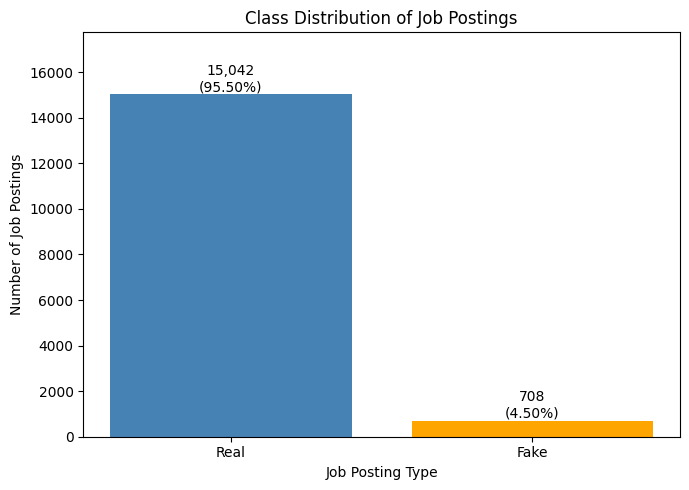

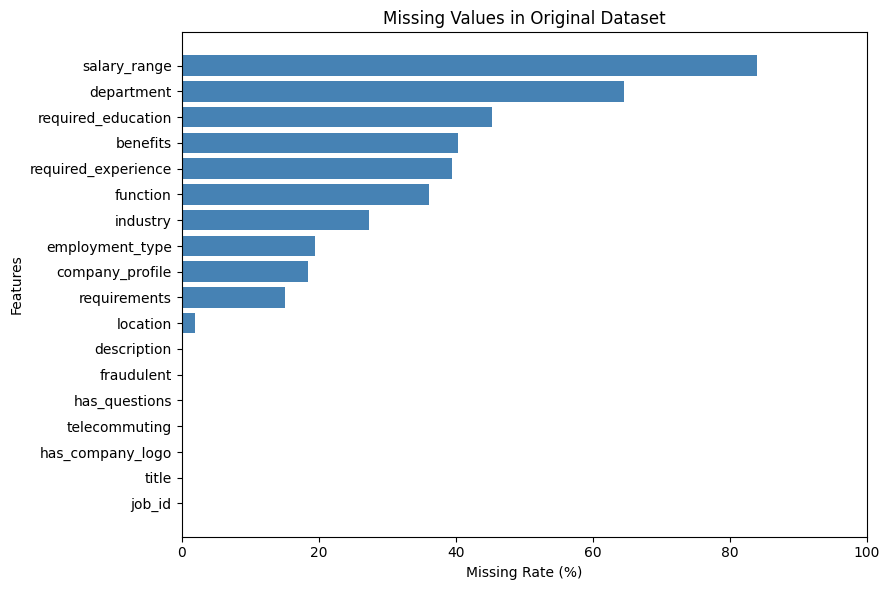

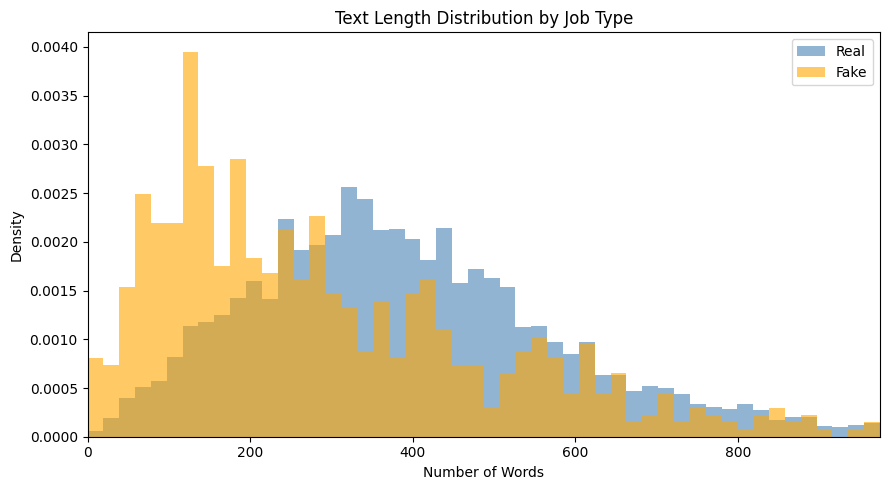

All three EDA charts saved.


In [5]:

# Step 12: Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files

# Chart 1: Class Balance

counts = jobs_clean["fraudulent"].value_counts().reindex(
    [0, 1], fill_value=0
)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Real", "Fake"],
    counts.values,
    color=["steelblue", "orange"]
)

for bar, count in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({count / len(jobs_clean) * 100:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Class Distribution of Job Postings")
ax.set_xlabel("Job Posting Type")
ax.set_ylabel("Number of Job Postings")
ax.set_ylim(0, counts.max() * 1.18)

plt.tight_layout()
plt.savefig("eda_class_balance.png", dpi=300)
plt.show()


# Chart 2: Missing Values (Original Dataset)

missing_rate = (
    df_original.isna().mean() * 100
    if "df_original" in globals()
    else None
)

# Read the original CSV to avoid using cleaned data
raw_df = pd.read_csv(FILE_NAME)
missing_rate = raw_df.isna().mean().sort_values() * 100

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    missing_rate.index,
    missing_rate.values,
    color="steelblue"
)

ax.set_title("Missing Values in Original Dataset")
ax.set_xlabel("Missing Rate (%)")
ax.set_ylabel("Features")
ax.set_xlim(0, 100)

plt.tight_layout()
plt.savefig("eda_missing_values.png", dpi=300)
plt.show()


# Chart 3: Text Length Distribution

eda_df = jobs_clean.copy()

eda_df["text_length"] = (
    eda_df["text_all"].str.split().str.len()
)

real_length = eda_df.loc[
    eda_df["fraudulent"] == 0, "text_length"
]

fake_length = eda_df.loc[
    eda_df["fraudulent"] == 1, "text_length"
]

fig, ax = plt.subplots(figsize=(9, 5))

# Use the 99th percentile only to set the display range
max_length = eda_df["text_length"].quantile(0.99)

bins = np.linspace(0, max_length, 51)

ax.hist(
    real_length,
    bins=bins,
    alpha=0.6,
    density=True,
    label="Real",
    color="steelblue"
)

ax.hist(
    fake_length,
    bins=bins,
    alpha=0.6,
    density=True,
    label="Fake",
    color="orange"
)

ax.set_title("Text Length Distribution by Job Type")
ax.set_xlabel("Number of Words")
ax.set_ylabel("Density")
ax.set_xlim(0, max_length)
ax.legend()

plt.tight_layout()
plt.savefig("eda_text_length.png", dpi=300)
plt.show()

print("All three EDA charts saved.")
